# Ejercicios de Chinookkota
Computación II  Tarea 8,
Quiero decir que pedir la mega guía a claude es algo que se debería considerar, facilita mucho el uso esta guía.

## Carga y preparación de los datos

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = "chinook_csvs"   # <- ajusta si tus CSV están en otra ruta
sns.set_theme(style="whitegrid", palette="deep")

def leer(nombre):
    return pd.read_csv(f"{DATA_DIR}/{nombre}")

album = leer("Album.csv")
artist = leer("Artist.csv")
customer = leer("Customer.csv")
employee = leer("Employee.csv")
genre = leer("Genre.csv")
invoice = leer("Invoice.csv")
invoice_line = leer("InvoiceLine.csv")
media = leer("MediaType.csv")
track = leer("Track.csv")

In [2]:
# Fechas a datetime y tabla de facturas
invoice["InvoiceDate"] = pd.to_datetime(invoice["InvoiceDate"])
invoice["Anio"] = invoice["InvoiceDate"].dt.year
invoice["Mes"] = invoice["InvoiceDate"].dt.month
facturas = invoice.rename(columns={"BillingCountry": "Pais"})

# Pistas: una fila por canción, con género, medio y artista
pistas = (track
          .merge(genre.rename(columns={"Name": "Genero"}), on="GenreId")
          .merge(media.rename(columns={"Name": "Medio"}), on="MediaTypeId")
          .merge(album, on="AlbumId")
          .merge(artist.rename(columns={"Name": "Artista"}), on="ArtistId")
          .rename(columns={"Name": "Pista"}))
pistas["Minutos"] = pistas["Milliseconds"] / 60000
pistas["MB"] = pistas["Bytes"] / 1e6

# Subconjuntos: solo audio < 15 min, y los 6 géneros con más pistas
audio = pistas[(pistas["Minutos"] < 15) & ~pistas["Medio"].str.contains("video")]
top_generos = audio["Genero"].value_counts().head(6).index
musica_top = audio[audio["Genero"].isin(top_generos)]

# Ventas: una fila por pista vendida
ventas = (invoice_line
          .merge(invoice, on="InvoiceId")
          .merge(track[["TrackId", "GenreId"]], on="TrackId")
          .merge(genre.rename(columns={"Name": "Genero"}), on="GenreId")
          .rename(columns={"BillingCountry": "Pais"}))
ventas["Importe"] = ventas["UnitPrice"] * ventas["Quantity"]
orden_ing = ventas.groupby("Genero")["Importe"].sum().nlargest(10).index

mensual = facturas.groupby(["Anio", "Mes"], as_index=False)["Total"].sum()

## Ejercicio 1
Con customer, un countplot horizontal del número de clientes por país, de mayor a menor.

Como la categoría va en y, la gráfica queda horizontal y los nombres se leen sin rotarlos. value_counts() ya devuelve los países ordenados de mayor a menor, así que su índice sirve directo como order.

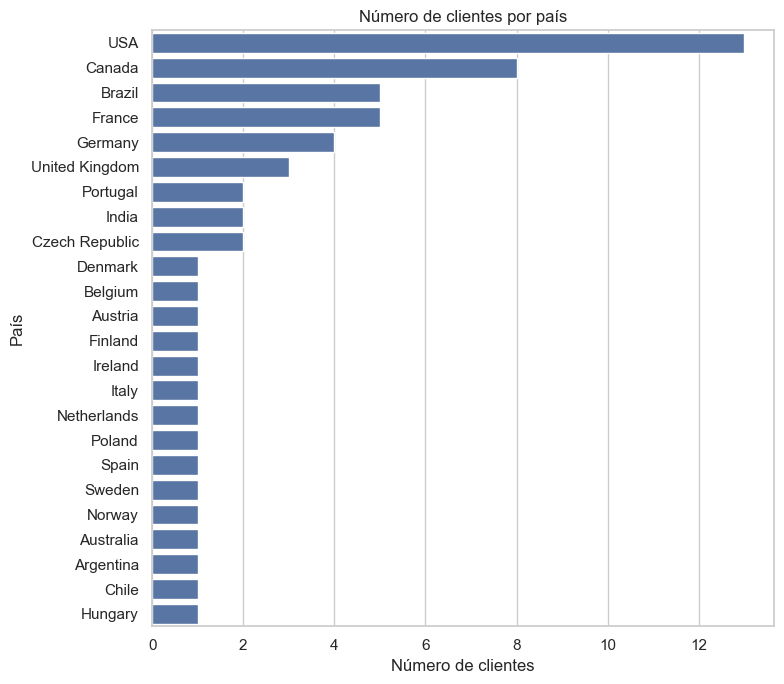

In [3]:
orden_paises = customer["Country"].value_counts().index

fig, ax = plt.subplots(figsize=(8, 7))
sns.countplot(data=customer, y="Country", order=orden_paises, ax=ax)
ax.set_title("Número de clientes por país")
ax.set_xlabel("Número de clientes")
ax.set_ylabel("País")
fig.tight_layout()
fig.savefig("ej1_clientes_por_pais.png", dpi=150, bbox_inches="tight")
plt.show()

## Ejercicio 2
Boxplot del Total de las facturas por país, solo para los 5 países con más ingresos. ¿Algún país tiene facturas atípicamente grandes?

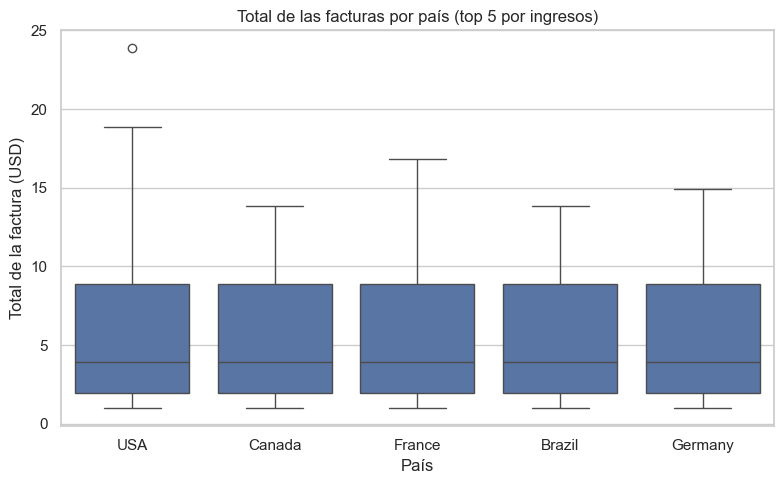

In [4]:
top5 = facturas.groupby("Pais")["Total"].sum().nlargest(5).index
fact_top5 = facturas[facturas["Pais"].isin(top5)]

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=fact_top5, x="Pais", y="Total", order=top5, ax=ax)
ax.set_title("Total de las facturas por país (top 5 por ingresos)")
ax.set_xlabel("País")
ax.set_ylabel("Total de la factura (USD)")
fig.tight_layout()
fig.savefig("ej2_boxplot_total_por_pais.png", dpi=150, bbox_inches="tight")
plt.show()

Se aprecia que USA tiene más variaciones en sus facturas, esto quiere decir que es el país que tiene facturas más atipica


## Ejercicio 3
Ingresos totales que atiende cada representante de soporte.

customer y employee tienen ambas FirstName y LastName, así que antes de unir armo una sola columna Representante y me quedo solo con lo necesario. Así no aparecen columnas _x / _y. La unión con employee usa left_on y right_on porque la columna se llama distinto en cada tabla.

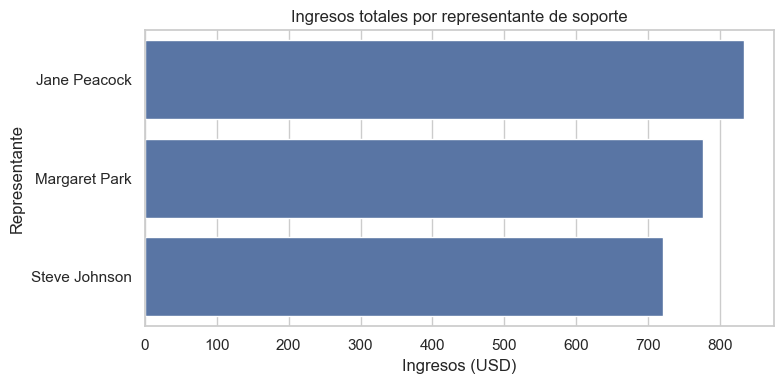

Representante
Jane Peacock     833.04
Margaret Park    775.40
Steve Johnson    720.16
Name: Total, dtype: float64

In [6]:
emp = employee[["EmployeeId", "FirstName", "LastName"]].copy()
emp["Representante"] = emp["FirstName"] + " " + emp["LastName"]
emp = emp[["EmployeeId", "Representante"]]

ingresos_rep = (invoice
                .merge(customer[["CustomerId", "SupportRepId"]], on="CustomerId")
                .merge(emp, left_on="SupportRepId", right_on="EmployeeId"))

orden_rep = (ingresos_rep.groupby("Representante")["Total"]
             .sum().sort_values(ascending=False).index)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=ingresos_rep, x="Total", y="Representante", order=orden_rep,
            estimator="sum", errorbar=None, ax=ax)
ax.set_title("Ingresos totales por representante de soporte")
ax.set_xlabel("Ingresos (USD)")
ax.set_ylabel("Representante")
fig.tight_layout()
fig.savefig("ej3_ingresos_por_representante.png", dpi=150, bbox_inches="tight")
plt.show()

ingresos_rep.groupby("Representante")["Total"].sum().sort_values(ascending=False).round(2)

## Ejercicio 4
Figura de 1×2 con sharey=True: a la izquierda el violinplot de duración para Rock y Latin, a la derecha el stripplot de los mismos datos.

Con sharey=True las dos gráficas comparten la escala vertical, así que se pueden comparar directamente.

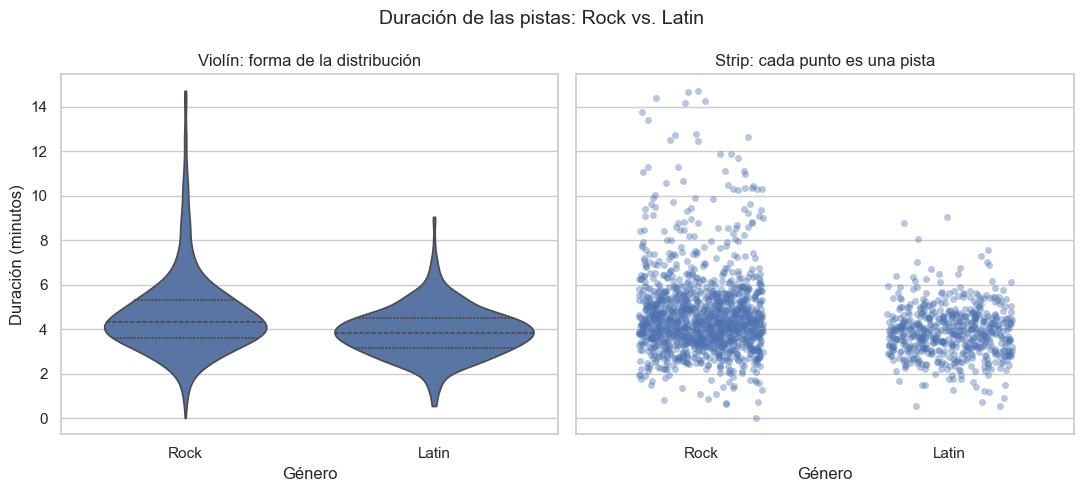

In [7]:
dos = audio[audio["Genero"].isin(["Rock", "Latin"])]
orden2 = ["Rock", "Latin"]

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
sns.violinplot(data=dos, x="Genero", y="Minutos", order=orden2,
               inner="quart", cut=0, ax=axes[0])
sns.stripplot(data=dos, x="Genero", y="Minutos", order=orden2,
              alpha=0.4, jitter=0.25, ax=axes[1])

axes[0].set_title("Violín: forma de la distribución")
axes[1].set_title("Strip: cada punto es una pista")
axes[0].set_ylabel("Duración (minutos)")
axes[1].set_ylabel("")
for ax in axes:
    ax.set_xlabel("Género")

fig.suptitle("Duración de las pistas: Rock vs. Latin", fontsize=14)
fig.tight_layout()
fig.savefig("ej4_violin_strip.png", dpi=150, bbox_inches="tight")
plt.show()

## Ejercicio 5
Tablero de 2×3 con seis gráficas distintas. Cada panel lleva título y etiquetas de ejes en español, la figura tiene suptitle y se guarda como PNG a 200 dpi.

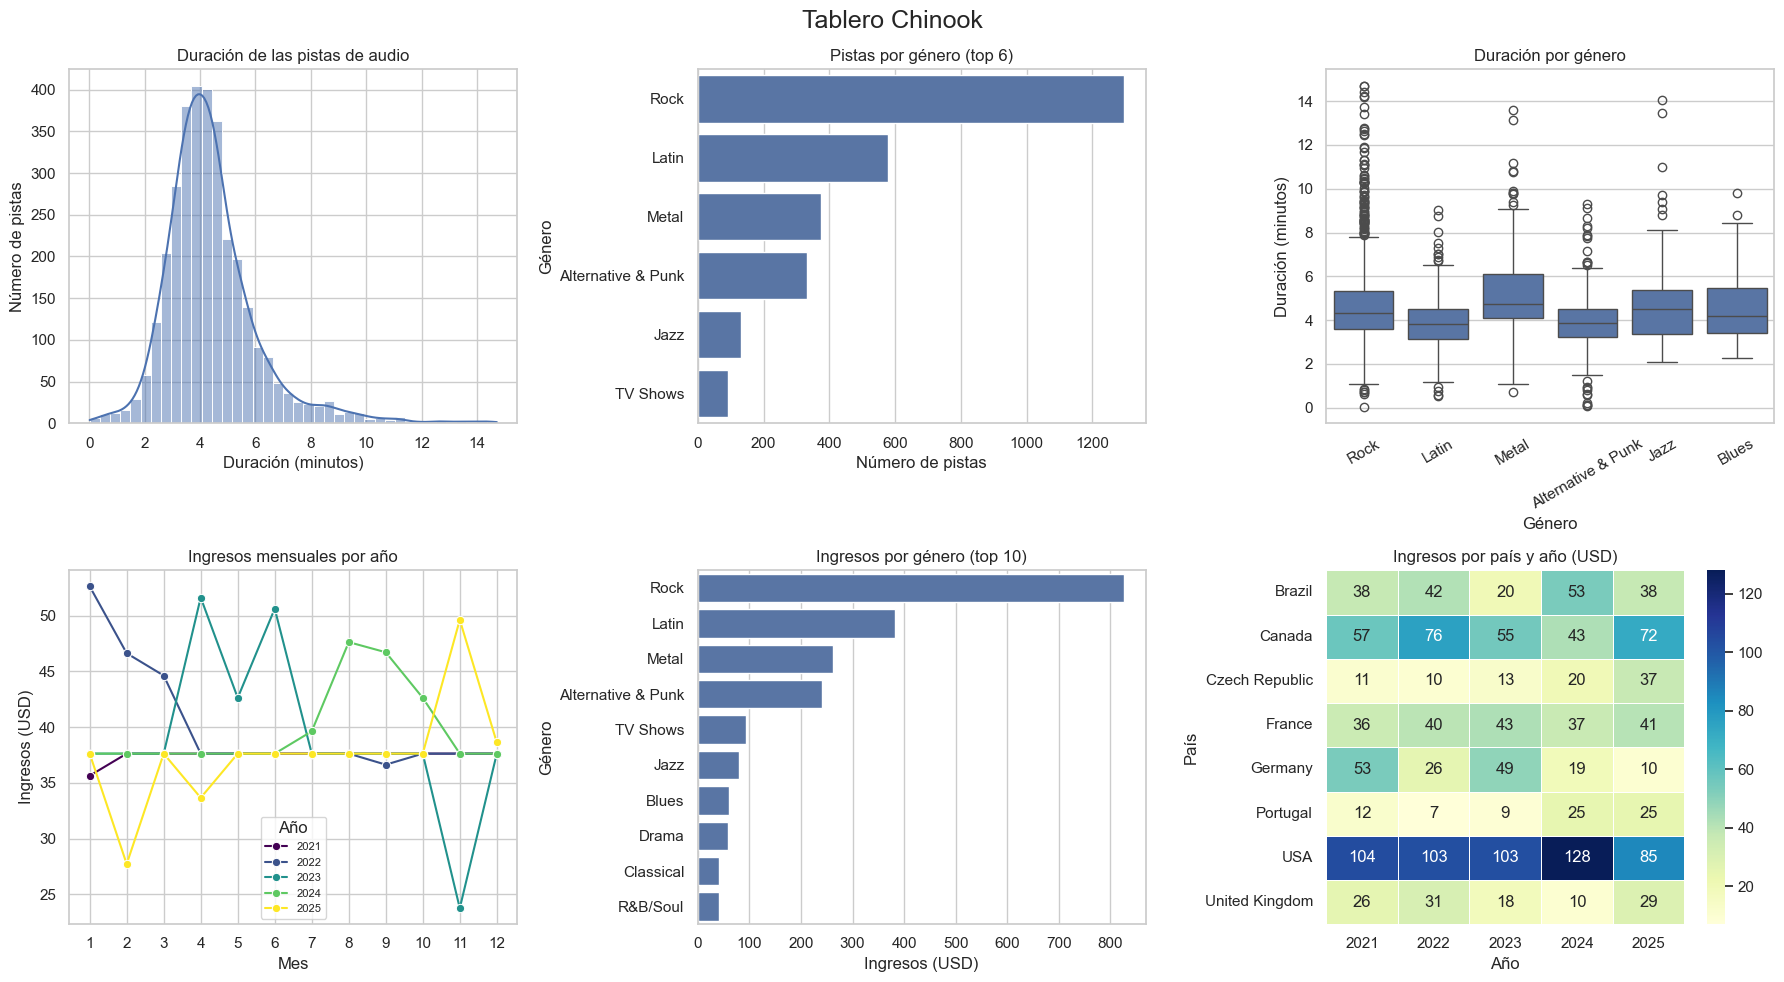

In [8]:
top_paises8 = facturas.groupby("Pais")["Total"].sum().nlargest(8).index
tabla_ing = (facturas[facturas["Pais"].isin(top_paises8)]
             .pivot_table(index="Pais", columns="Anio",
                          values="Total", aggfunc="sum"))
orden_gen = pistas["Genero"].value_counts().head(6).index

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# (0,0) histograma
sns.histplot(data=audio, x="Minutos", bins=40, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Duración de las pistas de audio")
axes[0, 0].set_xlabel("Duración (minutos)")
axes[0, 0].set_ylabel("Número de pistas")

# (0,1) countplot
sns.countplot(data=pistas, y="Genero", order=orden_gen, ax=axes[0, 1])
axes[0, 1].set_title("Pistas por género (top 6)")
axes[0, 1].set_xlabel("Número de pistas")
axes[0, 1].set_ylabel("Género")

# (0,2) boxplot
sns.boxplot(data=musica_top, x="Genero", y="Minutos", order=top_generos, ax=axes[0, 2])
axes[0, 2].set_title("Duración por género")
axes[0, 2].set_xlabel("Género")
axes[0, 2].set_ylabel("Duración (minutos)")
axes[0, 2].tick_params(axis="x", rotation=30)

# (1,0) lineplot
sns.lineplot(data=mensual, x="Mes", y="Total", hue="Anio",
             marker="o", palette="viridis", ax=axes[1, 0])
axes[1, 0].set_title("Ingresos mensuales por año")
axes[1, 0].set_xlabel("Mes")
axes[1, 0].set_ylabel("Ingresos (USD)")
axes[1, 0].set_xticks(range(1, 13))
axes[1, 0].legend(title="Año", fontsize=8)

# (1,1) barplot con suma
sns.barplot(data=ventas, x="Importe", y="Genero", order=orden_ing,
            estimator="sum", errorbar=None, ax=axes[1, 1])
axes[1, 1].set_title("Ingresos por género (top 10)")
axes[1, 1].set_xlabel("Ingresos (USD)")
axes[1, 1].set_ylabel("Género")

# (1,2) heatmap
sns.heatmap(tabla_ing, annot=True, fmt=".0f", cmap="YlGnBu",
            linewidths=0.5, ax=axes[1, 2])
axes[1, 2].set_title("Ingresos por país y año (USD)")
axes[1, 2].set_xlabel("Año")
axes[1, 2].set_ylabel("País")

fig.suptitle("Tablero Chinook", fontsize=18)
fig.tight_layout()
fig.savefig("tablero_chinook.png", dpi=200, bbox_inches="tight")
plt.show()

## Meme

mi meme favorito profe adjunto link: https://vt.tiktok.com/ZSp8vw1gv/

¿Por qué? Combina mi chiste favorito y el formato de meme que más me gusta (Baki)

Mención honorifica: https://www.tiktok.com/@mandy_tvt/video/7273185658825444613?is_from_webapp=1&sender_device=pc

